# Retail Sales Analysis and Predictive Modeling Using Python

## Project Overview

This project explores retail transaction data to identify sales patterns, examine factors associated with sales performance, and develop a machine learning model to predict sales.

Using the Superstore dataset, the analysis combines exploratory data analysis, data preprocessing, feature engineering, and K-Nearest Neighbors (KNN) regression to investigate retail sales behaviour.

The project also evaluates model performance using different cross-validation techniques to examine how the choice of validation method influences predictive accuracy.

## Project Objectives

- Explore retail sales data and identify key patterns and trends.
- Examine sales distributions across product categories, regions, customer segments, and shipping methods.
- Investigate relationships between numerical variables.
- Prepare the dataset for machine learning through data preprocessing and feature engineering.
- Develop a K-Nearest Neighbors regression model to predict sales.
- Evaluate predictive performance using multiple validation techniques.
- Interpret the results and identify potential limitations.

## Dataset

The analysis uses the Superstore dataset, which contains retail transaction information, including order dates, customer details, product categories, sales, profit, and shipping information.

The target variable for the regression analysis is **Sales**.

## Tools and Technologies

- **Python:** Core programming language
- **Pandas:** Data manipulation and analysis
- **NumPy:** Numerical computations
- **Matplotlib and Seaborn:** Data visualization
- **Scikit-learn:** Data preprocessing, KNN regression, cross-validation, and model evaluation

## Project Structure

1. Data Loading and Initial Exploration
2. Exploratory Data Analysis
3. Data Preprocessing and Feature Engineering
4. K-Nearest Neighbors Regression
5. Model Evaluation and Performance Comparison
6. Findings, Limitations, and Recommendations

## Expected Outcome

The project aims to demonstrate how Python-based data analysis and machine learning techniques can be applied to retail transaction data to uncover business insights and assess the potential for sales prediction.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, LeaveOneOut, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.impute import SimpleImputer

###Loading the Dataset

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/NdAbdulsalaam/Superstore_EDA-Profit_Prediction/main/Superstore.csv", encoding='latin1')

In [ ]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



### Exploratory Data Analysis (EDA)


In [ ]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [ ]:
sns.set_style("whitegrid")
plt.figure(figsize=(12, 6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

Text(0.5, 0, 'Sales Amount')

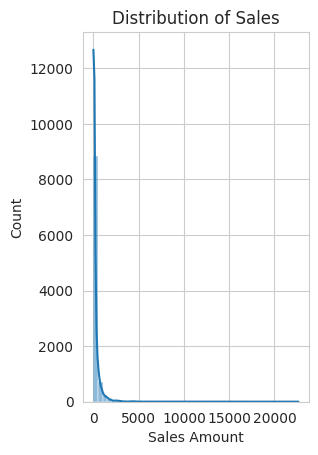

In [ ]:
plt.subplot(1, 2, 1)
sns.histplot(df['Sales'], bins=45, kde=True)
plt.title('Distribution of Sales')
plt.xlabel('Sales Amount')

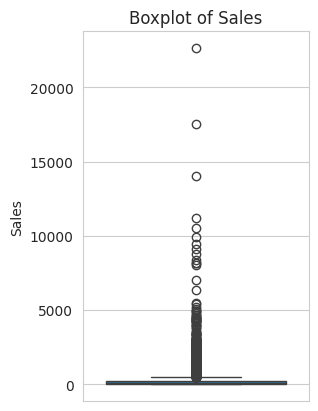

In [ ]:
plt.subplot(1, 2, 2)
sns.boxplot(y=df['Sales'])
plt.title('Boxplot of Sales')
plt.show()

Text(0.5, 1.0, 'Total Sales by Category')

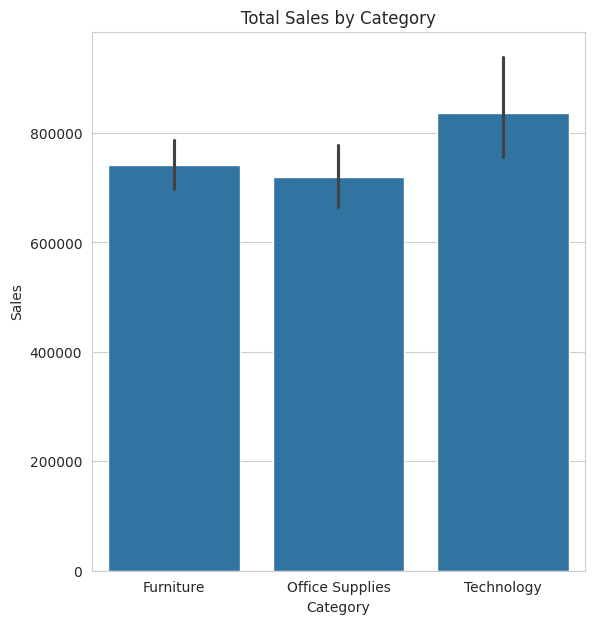

In [ ]:
plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1)
sns.barplot(x='Category', y='Sales', data=df, estimator=np.sum)
plt.title('Total Sales by Category')

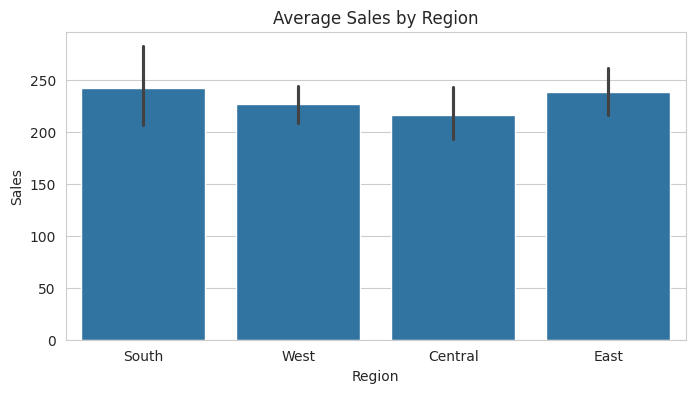

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(x='Region', y='Sales', data=df, estimator=np.mean)
plt.title('Average Sales by Region')
plt.show()

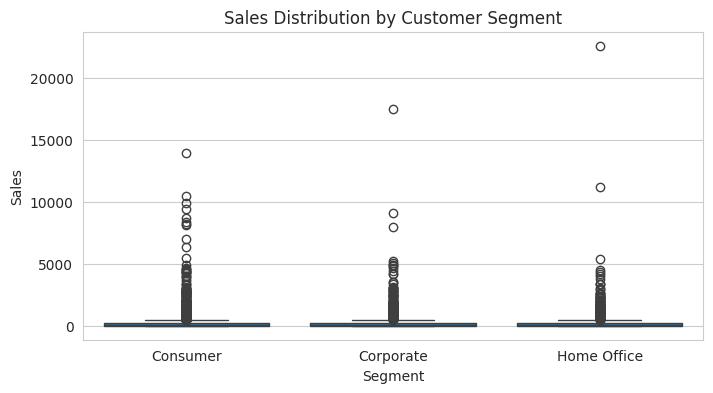

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x='Segment', y='Sales', data=df)
plt.title('Sales Distribution by Customer Segment')
plt.show()

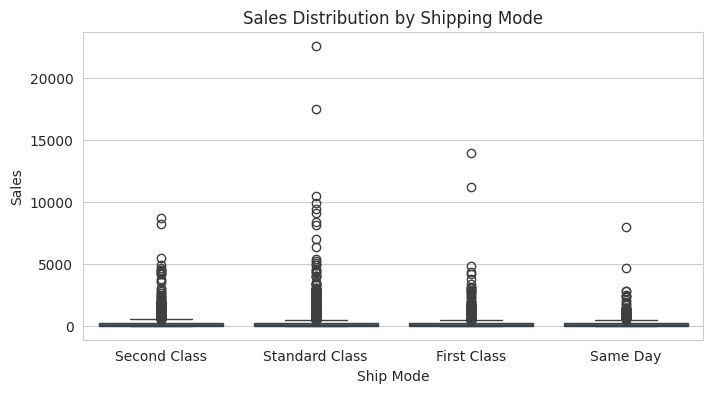

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x='Ship Mode', y='Sales', data=df)
plt.title('Sales Distribution by Shipping Mode')
plt.show()

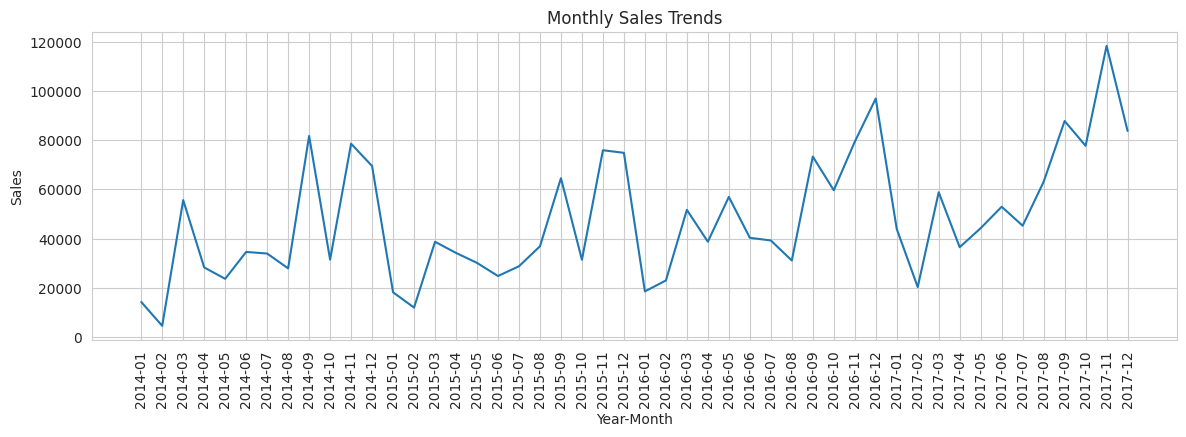

In [ ]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y', errors='coerce')

df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month

monthly_sales = df.groupby(['Order Year', 'Order Month'])['Sales'].sum().reset_index()
monthly_sales['Year-Month'] = monthly_sales['Order Year'].astype(str) + '-' + monthly_sales['Order Month'].astype(str).str.zfill(2)

plt.figure(figsize=(14, 4))
sns.lineplot(x='Year-Month', y='Sales', data=monthly_sales)
plt.title('Monthly Sales Trends')
plt.xticks(rotation=90)
plt.show()

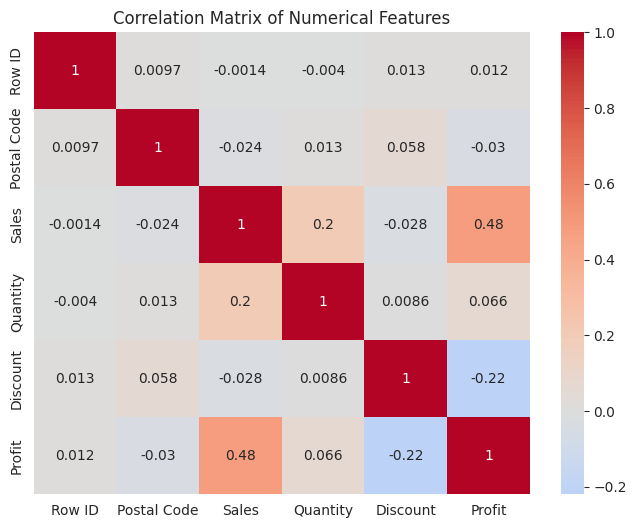

In [ ]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [ ]:
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Sales'] < lower_bound) | (df['Sales'] > upper_bound)]
print(f"\nNumber of outliers in Sales: {len(outliers)}")
print(f"Percentage of outliers: {len(outliers)/len(df)*100:.2f}%")


Number of outliers in Sales: 1167
Percentage of outliers: 11.68%




### Data Pre-processing


In [ ]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y', errors='coerce') # Changed format to '%m/%d/%Y' and added errors='coerce'
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y', errors='coerce') # Changed format to '%m/%d/%Y' and added errors='coerce'
df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order Day'] = df['Order Date'].dt.day
df['Order Weekday'] = df['Order Date'].dt.weekday

In [ ]:
df['Shipping Delay'] = (df['Ship Date'] - df['Order Date']).dt.days

categorical_cols = ['Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [ ]:
columns_to_drop = ['Row ID', 'Order ID', 'Customer ID', 'Customer Name', 'Product ID', 'Product Name',
                  'Country', 'City', 'State', 'Postal Code', 'Order Date', 'Ship Date']
df_encoded = df_encoded.drop(columns=columns_to_drop)

X = df_encoded.drop(columns=['Sales'])
y = df_encoded['Sales']

In [ ]:
print("Preprocessed data shape:", X.shape)
print("\nFirst few rows of features:")
display(X.head())

Preprocessed data shape: (9994, 34)

First few rows of features:


,Quantity,Discount,Profit,Order Year,Order Month,Order Day,Order Weekday,Shipping Delay,Category_Office Supplies,Category_Technology,...,Sub-Category_Supplies,Sub-Category_Tables,Region_East,Region_South,Region_West,Segment_Corporate,Segment_Home Office,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class
0,2,0.00,41.9136,2016,11,8,1,3,False,False,...,False,False,False,True,False,False,False,False,True,False
1,3,0.00,219.5820,2016,11,8,1,3,False,False,...,False,False,False,True,False,False,False,False,True,False
2,2,0.00,6.8714,2016,6,12,6,4,True,False,...,False,False,False,False,True,True,False,False,True,False
3,5,0.45,-383.0310,2015,10,11,6,7,False,False,...,False,True,False,True,False,False,False,False,False,True
4,2,0.20,2.5164,2015,10,11,6,7,True,False,...,False,False,False,True,False,False,False,False,False,True




### KNN Regression


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
knn_pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(n_neighbors=5)
)

scoring = {
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error',
    'R2': 'r2'
}

# 1. K-Fold Cross-Validation (5 folds)
print("K-Fold Cross-Validation Results:")
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
kfold_results = cross_val_score(knn_pipeline, X_train, y_train, cv=kfold, scoring='neg_root_mean_squared_error')
print(f"Average RMSE: {-kfold_results.mean():.2f}")

kfold_metrics = {}
for metric_name, metric_scoring in scoring.items():
    scores = cross_val_score(knn_pipeline, X_train, y_train, cv=kfold, scoring=metric_scoring)
    if metric_name in ['RMSE', 'MAE']:
        scores = -scores  # Convert back to positive
    kfold_metrics[metric_name] = scores.mean()

print("\nK-Fold Metrics:")
for metric, value in kfold_metrics.items():
    print(f"{metric}: {value:.4f}")

K-Fold Cross-Validation Results:
Average RMSE: 362.49

K-Fold Metrics:
RMSE: 362.4930
MAE: 157.4853
R2: 0.5608


In [ ]:
 #2. Time Series Split Cross-Validation
print("\nTime Series Split Cross-Validation Results:")
# Sort by Order Year and Order Month to maintain temporal order
X_train_sorted = X_train.sort_values(['Order Year', 'Order Month'])
y_train_sorted = y_train[X_train_sorted.index]

tscv = TimeSeriesSplit(n_splits=5)
tscv_results = cross_val_score(knn_pipeline, X_train_sorted, y_train_sorted, cv=tscv, scoring='neg_root_mean_squared_error')
print(f"Average RMSE: {-tscv_results.mean():.2f}")

tscv_metrics = {}
for metric_name, metric_scoring in scoring.items():
    scores = cross_val_score(knn_pipeline, X_train_sorted, y_train_sorted, cv=tscv, scoring=metric_scoring)
    if metric_name in ['RMSE', 'MAE']:
        scores = -scores
    tscv_metrics[metric_name] = scores.mean()

print("\nTime Series Split Metrics:")
for metric, value in tscv_metrics.items():
    print(f"{metric}: {value:.4f}")


Time Series Split Cross-Validation Results:
Average RMSE: 388.95

Time Series Split Metrics:
RMSE: 388.9541
MAE: 165.2478
R2: 0.5322


In [ ]:
# 3. Leave-One-Out Cross-Validation (on a subset for efficiency)
print("\nLeave-One-Out Cross-Validation Results (on subset):")
# Use a subset for LOOCV due to computational intensity
subset_size = 100
X_subset = X_train.iloc[:subset_size]
y_subset = y_train.iloc[:subset_size]

loocv = LeaveOneOut()
loocv_results = cross_val_score(knn_pipeline, X_subset, y_subset, cv=loocv, scoring='neg_root_mean_squared_error')
print(f"Average RMSE: {-loocv_results.mean():.2f}")


Leave-One-Out Cross-Validation Results (on subset):
Average RMSE: 234.56


In [ ]:
# Get all metrics for LOOCV
loocv_metrics = {}
for metric_name, metric_scoring in scoring.items():
    scores = cross_val_score(knn_pipeline, X_subset, y_subset, cv=loocv, scoring=metric_scoring)
    if metric_name in ['RMSE', 'MAE']:
        scores = -scores
    loocv_metrics[metric_name] = scores.mean()

print("\nLOOCV Metrics:")
for metric, value in loocv_metrics.items():
    print(f"{metric}: {value:.4f}")

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, Unde


LOOCV Metrics:
RMSE: 234.5575
MAE: 234.5575
R2: nan


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, Unde

In [ ]:
# Fit the model on the entire training set and evaluate on test set
knn_pipeline.fit(X_train, y_train)
y_pred = knn_pipeline.predict(X_test)

# Calculate RMSE using np.sqrt
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred)) # Changed to use np.sqrt

test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print("\nTest Set Performance:")
print(f"RMSE: {test_rmse:.2f}")
print(f"MAE: {test_mae:.2f}")
print(f"R2: {test_r2:.4f}")


Test Set Performance:
RMSE: 611.88
MAE: 172.82
R2: 0.3662



### Results Visualization and Comparison


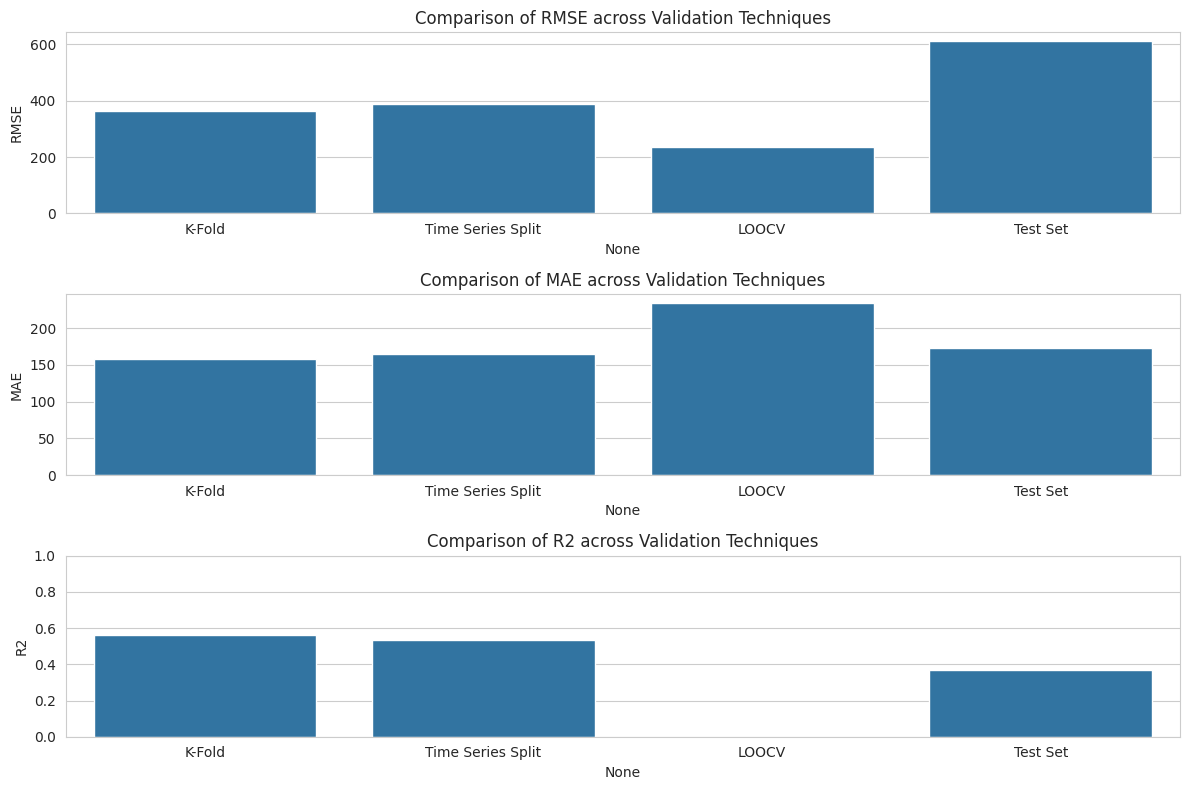

In [ ]:
metrics_df = pd.DataFrame({
    'K-Fold': kfold_metrics,
    'Time Series Split': tscv_metrics,
    'LOOCV': loocv_metrics,
    'Test Set': {'RMSE': test_rmse, 'MAE': test_mae, 'R2': test_r2}
}).T

# Plot comparison
plt.figure(figsize=(12, 8))

for i, metric in enumerate(['RMSE', 'MAE', 'R2'], 1):
    plt.subplot(3, 1, i)
    sns.barplot(x=metrics_df.index, y=metric, data=metrics_df)
    plt.title(f'Comparison of {metric} across Validation Techniques')
    if metric == 'R2':
        plt.ylim(0, 1)  # R2 is between 0 and 1
    plt.ylabel(metric)

plt.tight_layout()
plt.show()

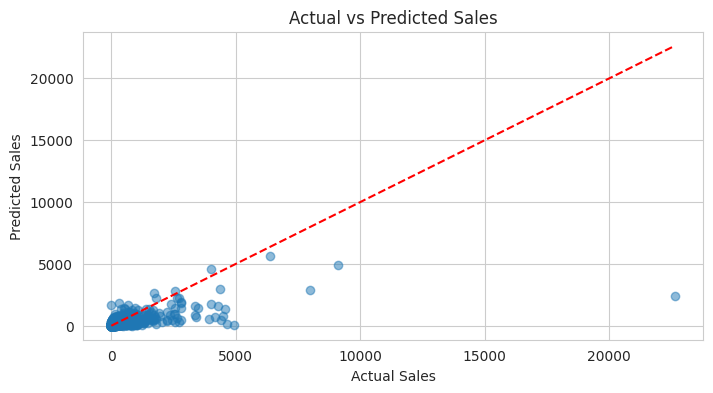

In [ ]:
plt.figure(figsize=(8, 4))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.show()

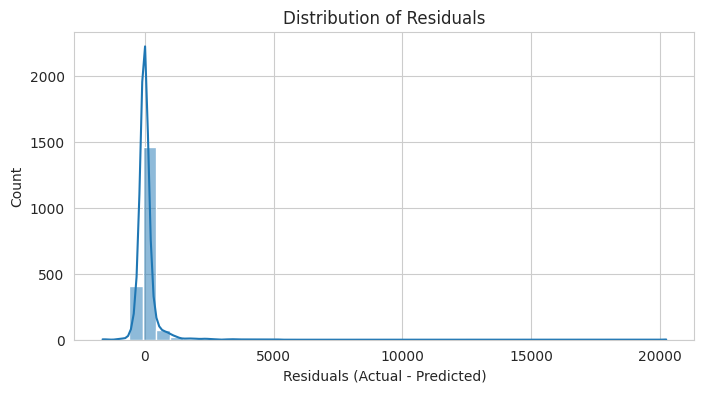

In [ ]:
residuals = y_test - y_pred
plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=42, kde=True)
plt.xlabel('Residuals (Actual - Predicted)')
plt.title('Distribution of Residuals')
plt.show()

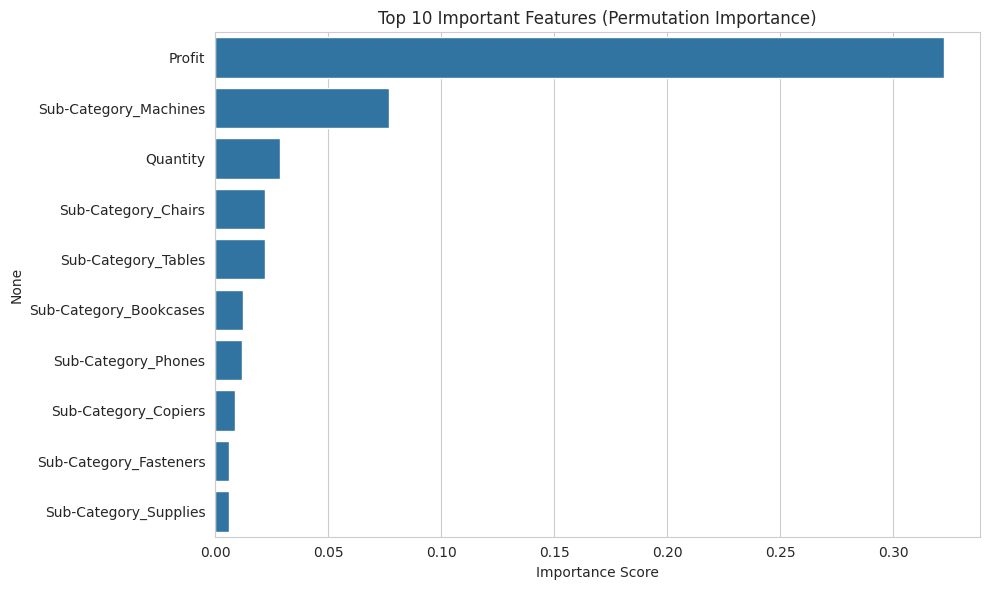

In [ ]:
result = permutation_importance(knn_pipeline, X_test, y_test, n_repeats=10, random_state=42)

# Get top 10 important features
sorted_idx = result.importances_mean.argsort()[::-1][:10]

plt.figure(figsize=(10, 6))
sns.barplot(x=result.importances_mean[sorted_idx], y=X.columns[sorted_idx])
plt.title('Top 10 Important Features (Permutation Importance)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

###Findings and Evaluation

**Exploratory Data Analysis Findings**

The exploratory analysis of the 9,994 retail transactions revealed several characteristics of the Superstore dataset.

The distribution of Sales is positively skewed, indicating that a substantial proportion of transactions involve relatively small sales values, while a smaller number of transactions account for considerably larger amounts. This distribution is also reflected in the descriptive statistics: average transaction sales are approximately $229.86, compared with a median of $54.49. The difference highlights the influence of high-value transactions on the overall distribution.

The analysis of product categories indicates that Technology generates the highest total sales, followed by Furniture and Office Supplies. Regional comparisons show that the West region records the highest average transaction sales. The visualisations also provide insight into differences in sales distributions across customer segments and shipping methods.

The temporal analysis, based on monthly aggregated sales, suggests fluctuations in sales activity across the observation period, with visible increases towards certain year-end periods. These patterns indicate that transaction timing may be relevant when examining retail sales behaviour.

The outlier analysis identified 1,167 observations beyond the interquartile range boundaries, representing approximately 11.68% of the dataset. Given the substantial right-skewness of Sales, these observations may influence model estimation and evaluation, particularly for a distance-based algorithm such as K-Nearest Neighbors.

**Model Performance and Evaluation**

A K-Nearest Neighbors (KNN) regression model was implemented using a Scikit-learn pipeline incorporating feature standardisation and a KNN regressor with five neighbours. The dataset was divided into training and testing subsets using an 80:20 split, and model performance was assessed using Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and the coefficient of determination (R²).

The five-fold cross-validation results indicate moderate explanatory performance, with an average R² of 0.5608. The Time Series Split produces a slightly higher RMSE and MAE, alongside a lower R² of 0.5322. This suggests that the model performs somewhat less effectively when evaluated using sequential training and validation subsets.

More importantly, performance on the independent test set is weaker, with an R² of 0.3662 and an RMSE of 611.88. The difference between the cross-validation and test-set results suggests that the model's performance is sensitive to the evaluation sample. In particular, the substantially higher test RMSE indicates that some prediction errors are considerably larger on unseen observations.

The MAE of 172.82 indicates that the model's average absolute prediction error on the test set is approximately 172.82 sales units. The difference between RMSE and MAE further suggests the presence of relatively large prediction errors, consistent with the highly skewed distribution of the target variable.

**Comparison of Validation Techniques**

The three validation approaches provide different perspectives on model performance; however, their results should not be interpreted as directly interchangeable.

Five-fold cross-validation provides an estimate of performance across multiple partitions of the training data. Its results are relatively consistent across folds, although the independent test-set results indicate that this estimate does not fully reflect the model's performance on the held-out observations.

Time Series Split produces slightly weaker results than shuffled K-Fold validation. This difference may reflect changes in the distribution of transactions over time. However, the current implementation first randomly partitions the dataset and subsequently sorts the training observations by year and month. Consequently, it does not constitute a fully chronological evaluation of the original dataset. A chronological train-test split would be more appropriate for assessing the model's ability to predict future sales using historical observations.

Leave-One-Out Cross-Validation was performed on a subset of 100 training observations to limit computational requirements. It produced an RMSE of 234.56. However, its results cannot be directly compared with those of K-Fold or Time Series Split because it uses a much smaller evaluation sample. Furthermore, R² is undefined in this implementation because each validation fold contains only one observation. The reported LOOCV result should therefore be treated as a limited supplementary experiment rather than evidence of superior predictive performance.

**Limitations and Areas for Improvement**

Several limitations should be considered when interpreting the results.

First, the Sales variable exhibits substantial positive skewness and contains a considerable number of outliers. Since KNN regression relies on distances between observations, extreme values and differences in feature distributions may affect the identification of neighbouring observations and the resulting predictions.

Second, the current feature set includes Profit as an explanatory variable for Sales. This creates a target leakage concern because Profit is calculated using Sales. As a result, the current model may have access to information that would not be independently available when predicting sales in a real business application. Profit should be excluded from the predictor variables, and the model should be retrained before its predictive performance is treated as valid.

Third, although numerical features are standardised and categorical variables are one-hot encoded, the dataset combines transaction quantities, discount information, temporal features, shipping information, and categorical product characteristics. The effectiveness of representing these different feature types through the current KNN approach may be limited.

Additionally, the temporal validation procedure requires improvement. Sorting an already randomly partitioned training set does not fully preserve the chronological structure of the original dataset. A properly ordered temporal split would provide a more meaningful assessment of performance under future-facing prediction conditions.

Finally, the current implementation uses a fixed value of five neighbours rather than systematically evaluating alternative values of K. Model performance may therefore be improved through hyperparameter optimisation and more deliberate feature selection.

**Recommendations**

The analysis provides several opportunities for further development:

1. Remove Profit from the predictor variables and retrain the model using information available at the time of prediction.

2. Explore additional transaction-level and temporal features that may capture differences in customer purchasing behaviour and sales patterns.

3. Compare KNN regression with approaches such as Random Forest and Gradient Boosting to assess whether more flexible algorithms can better capture nonlinear relationships.

4. Evaluate different values of K and distance-weighting strategies to identify a more suitable KNN configuration.

5. Investigate appropriate transformations of the Sales variable and assess their effect on prediction errors.

6. Use a chronological train-test split and time-aware validation to better reflect the practical task of forecasting sales using historical data.

7. Further investigate transactions with particularly large residuals to understand where the model performs least effectively.

**Overall Assessment**

This project demonstrates the application of Python-based data analysis and machine learning techniques to a retail transaction dataset. It combines exploratory data analysis, data preprocessing, feature engineering, KNN regression, and multiple model evaluation approaches within a single analytical workflow.

The findings highlight the importance of understanding the underlying data distribution and selecting appropriate validation procedures when developing predictive models. Although the current KNN implementation provides a useful baseline, the independent test-set results and identified methodological limitations indicate that further refinement is necessary before the model can be considered suitable for practical sales prediction.

Overall, the project provides a foundation for more advanced retail analytics by demonstrating how transaction data can be examined, prepared, and used to investigate the potential of machine learning for sales prediction.
